
# Clothing Types Image Classification

### SAIA 2113 — Machine Learning Assignment 1

## Phase 2: Data Preprocessing



## 1. Environment Setup and Dataset Loading

### 1.1 Google Drive Connection



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



### 1.2 Project Directory Configuration

Configure the input dataset directory and output
directories for data preprocessing.

The original cleaned dataset is preserved
without modification.


In [2]:
from pathlib import Path

# Project directories
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

CLEAN_DIR = PROJECT_ROOT / "cleaned_dataset"
REPORT_DIR = PROJECT_ROOT / "reports"

PROCESSED_DIR = PROJECT_ROOT / "processed_dataset"
PREPROCESSING_DIR = REPORT_DIR / "preprocessing"

# Verify existing dataset
if not CLEAN_DIR.is_dir():
    raise FileNotFoundError("Cleaned dataset not found.")

# Create preprocessing output directories
for folder in [PROCESSED_DIR, PREPROCESSING_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["t-shirt", "pants", "dress", "shorts", "outwear"]

SEED = 42
IMAGE_SIZE = (224, 224)

print("Preprocessing environment initialized!")
print("Input dataset:", CLEAN_DIR)
print("Output directory:", PROCESSED_DIR)
print("Preprocessing reports:", PREPROCESSING_DIR)


Preprocessing environment initialized!
Input dataset: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/cleaned_dataset
Output directory: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/processed_dataset
Preprocessing reports: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing



### 1.3 Load and Verify Cleaned Dataset

Load the final dataset manifest generated during
the data collection phase.

Verify image availability, class labels, and
class distribution before preprocessing.


In [3]:

import pandas as pd

MANIFEST_PATH = REPORT_DIR / "cleaned_dataset_manifest.csv"

# Load final dataset manifest
dataset_df = pd.read_csv(MANIFEST_PATH)

# Construct image paths
dataset_df["image_path"] = dataset_df[
    "cleaned_relative_path"
].apply(lambda path: str(CLEAN_DIR / path))

# Verify image availability
dataset_df["file_exists"] = dataset_df[
    "image_path"
].apply(lambda path: Path(path).is_file())

# Verify actual dataset files match the manifest
actual_files = {
    p.relative_to(CLEAN_DIR).as_posix()
    for p in CLEAN_DIR.rglob("*")
    if p.is_file()
}

expected_files = set(dataset_df["cleaned_relative_path"])

# Dataset validation
assert len(dataset_df) == 600, "Unexpected image count."
assert set(dataset_df["class"]) == set(CLASSES)
assert dataset_df["file_exists"].all(), "Missing image files."
assert dataset_df["decision"].eq("KEEP").all()
assert not dataset_df["cleaned_relative_path"].duplicated().any()
assert actual_files == expected_files

# Class distribution
class_counts = dataset_df["class"].value_counts()

assert class_counts.eq(120).all(), "Unexpected class distribution."

# Display dataset summary
print("DATASET LOADING SUMMARY")
print("=" * 40)

print("Total images:", len(dataset_df))
print("Total classes:", dataset_df["class"].nunique())
print("Missing images:", (~dataset_df["file_exists"]).sum())

print("\nClass distribution:")

display(
    dataset_df.groupby("class")
    .size()
    .reset_index(name="Images")
)

print("\nDataset preview:")

display(
    dataset_df[
        ["filename", "class", "cleaned_relative_path"]
    ].head()
)

print("\nDataset loaded and verified successfully!")


DATASET LOADING SUMMARY
Total images: 600
Total classes: 5
Missing images: 0

Class distribution:


,class,Images
0,dress,120
1,outwear,120
2,pants,120
3,shorts,120
4,t-shirt,120



Dataset preview:


,filename,class,cleaned_relative_path
0,train_56df5a3e-235c-4ea8-b7e7-9244f09ae974.jpg,t-shirt,t-shirt/train_56df5a3e-235c-4ea8-b7e7-9244f09a...
1,train_5da3e2de-dfef-43de-938f-89230c45cc95.jpg,t-shirt,t-shirt/train_5da3e2de-dfef-43de-938f-89230c45...
2,test_ffa2be27-0798-488d-b9de-254de2226667.jpg,t-shirt,t-shirt/test_ffa2be27-0798-488d-b9de-254de2226...
3,train_68fc2f45-6c5d-4a57-a3e7-2f6a72a4c486.jpg,t-shirt,t-shirt/train_68fc2f45-6c5d-4a57-a3e7-2f6a72a4...
4,train_1963940a-8c6c-4f2e-b746-1422413a6926.jpg,t-shirt,t-shirt/train_1963940a-8c6c-4f2e-b746-1422413a...



Dataset loaded and verified successfully!



## 2. Exploratory Data Analysis (EDA)

### 2.1 Image Characteristics Analysis

Analyze the characteristics of the cleaned clothing
dataset, including image dimensions, aspect ratios,
colour modes, brightness, and file sizes.

The analysis supports the selection of suitable
image preprocessing techniques.


In [4]:
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import numpy as np
import pandas as pd

eda_records = []

# Analyze every cleaned image
for _, row in tqdm(
    dataset_df.iterrows(),
    total=len(dataset_df),
    desc="Analyzing images"
):
    path = Path(row["image_path"])
    with Image.open(path) as img:
        original_mode = img.mode
        img = ImageOps.exif_transpose(img)
        width, height = img.size

        # Convert to grayscale for brightness analysis
        grayscale = np.asarray(
            img.convert("L"),
            dtype=np.float32
        )

        brightness = float(grayscale.mean())
        contrast = float(grayscale.std())
        # Determine image orientation
        if width > height:
            orientation = "Landscape"

        elif height > width:
            orientation = "Portrait"

        else:
            orientation = "Square"

    eda_records.append({
        "filename": row["filename"],
        "class": row["class"],
        "relative_path": row["cleaned_relative_path"],
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
        "orientation": orientation,
        "colour_mode": original_mode,
        "brightness": brightness,
        "contrast": contrast,
        "file_size_kb": path.stat().st_size / 1024
    })

eda_df = pd.DataFrame(eda_records)

# Save EDA results
eda_df.to_csv(
    PREPROCESSING_DIR / "image_characteristics.csv",
    index=False
)

print("IMAGE CHARACTERISTICS ANALYSIS")
print("=" * 45)

print("Total images analyzed:", len(eda_df))

display(eda_df.head())

print("\nAnalysis saved successfully!")


Analyzing images:   0%|          | 0/600 [00:00<?, ?it/s]

IMAGE CHARACTERISTICS ANALYSIS
Total images analyzed: 600


,filename,class,relative_path,width,height,aspect_ratio,orientation,colour_mode,brightness,contrast,file_size_kb
0,train_56df5a3e-235c-4ea8-b7e7-9244f09ae974.jpg,t-shirt,t-shirt/train_56df5a3e-235c-4ea8-b7e7-9244f09a...,400,533,0.750469,Portrait,RGB,154.671036,79.157730,20.754883
1,train_5da3e2de-dfef-43de-938f-89230c45cc95.jpg,t-shirt,t-shirt/train_5da3e2de-dfef-43de-938f-89230c45...,400,533,0.750469,Portrait,RGB,136.864365,43.760933,20.910156
2,test_ffa2be27-0798-488d-b9de-254de2226667.jpg,t-shirt,t-shirt/test_ffa2be27-0798-488d-b9de-254de2226...,400,469,0.852878,Portrait,RGB,163.763779,71.974937,16.513672
3,train_68fc2f45-6c5d-4a57-a3e7-2f6a72a4c486.jpg,t-shirt,t-shirt/train_68fc2f45-6c5d-4a57-a3e7-2f6a72a4...,400,533,0.750469,Portrait,RGB,127.855179,66.854462,23.500977
4,train_1963940a-8c6c-4f2e-b746-1422413a6926.jpg,t-shirt,t-shirt/train_1963940a-8c6c-4f2e-b746-1422413a...,533,400,1.332500,Landscape,RGB,100.161407,57.822117,16.859375



Analysis saved successfully!



### 2.2 Descriptive Statistics

Summarize the numerical characteristics of the
dataset to understand variations in image dimensions,
aspect ratios, brightness, contrast, and file sizes.


In [5]:
numerical_columns = [
    "width",
    "height",
    "aspect_ratio",
    "brightness",
    "contrast",
    "file_size_kb"
]
# Overall descriptive statistics
statistics = (
    eda_df[numerical_columns]
    .describe()
    .transpose()
    .round(2)
)
print("OVERALL DATASET STATISTICS")
display(statistics)

# Statistics by clothing class
class_statistics = (
    eda_df.groupby("class")[numerical_columns]
    .mean()
    .round(2)
)
print("\nAVERAGE CHARACTERISTICS BY CLASS")
display(class_statistics)

print("\nIMAGE ORIENTATION")
display(eda_df["orientation"].value_counts())

print("\nCOLOUR MODES")
display(eda_df["colour_mode"].value_counts())

# Save reports
statistics.to_csv(
    PREPROCESSING_DIR / "eda_statistics.csv"
)
class_statistics.to_csv(
    PREPROCESSING_DIR / "eda_class_statistics.csv"
)


OVERALL DATASET STATISTICS


,count,mean,std,min,25%,50%,75%,max
width,600.0,417.03,55.13,400.00,400.00,400.00,400.00,865.00
height,600.0,528.67,78.46,400.00,533.00,533.00,534.00,888.00
aspect_ratio,600.0,0.82,0.23,0.45,0.75,0.75,0.75,2.16
brightness,600.0,128.36,21.35,59.38,115.27,128.54,143.90,195.14
contrast,600.0,55.73,16.42,15.41,43.46,56.06,68.37,102.18
file_size_kb,600.0,27.73,11.33,11.41,20.41,24.49,31.44,85.66



AVERAGE CHARACTERISTICS BY CLASS


,width,height,aspect_ratio,brightness,contrast,file_size_kb
class,,,,,,
dress,405.80,555.42,0.75,131.26,58.17,33.18
outwear,413.88,543.33,0.79,125.78,59.32,24.89
pants,401.11,546.16,0.74,127.48,54.76,25.72
shorts,439.99,487.82,0.94,129.80,53.54,28.74
t-shirt,424.36,510.61,0.86,127.46,52.89,26.14



IMAGE ORIENTATION


,count
orientation,
Portrait,520
Landscape,67
Square,13



COLOUR MODES


,count
colour_mode,
RGB,600



### 2.3 Exploratory Data Analysis Visualizations

Visualize image dimensions, aspect ratio distribution,
image orientation, brightness, colour modes, and
brightness variation across clothing categories.


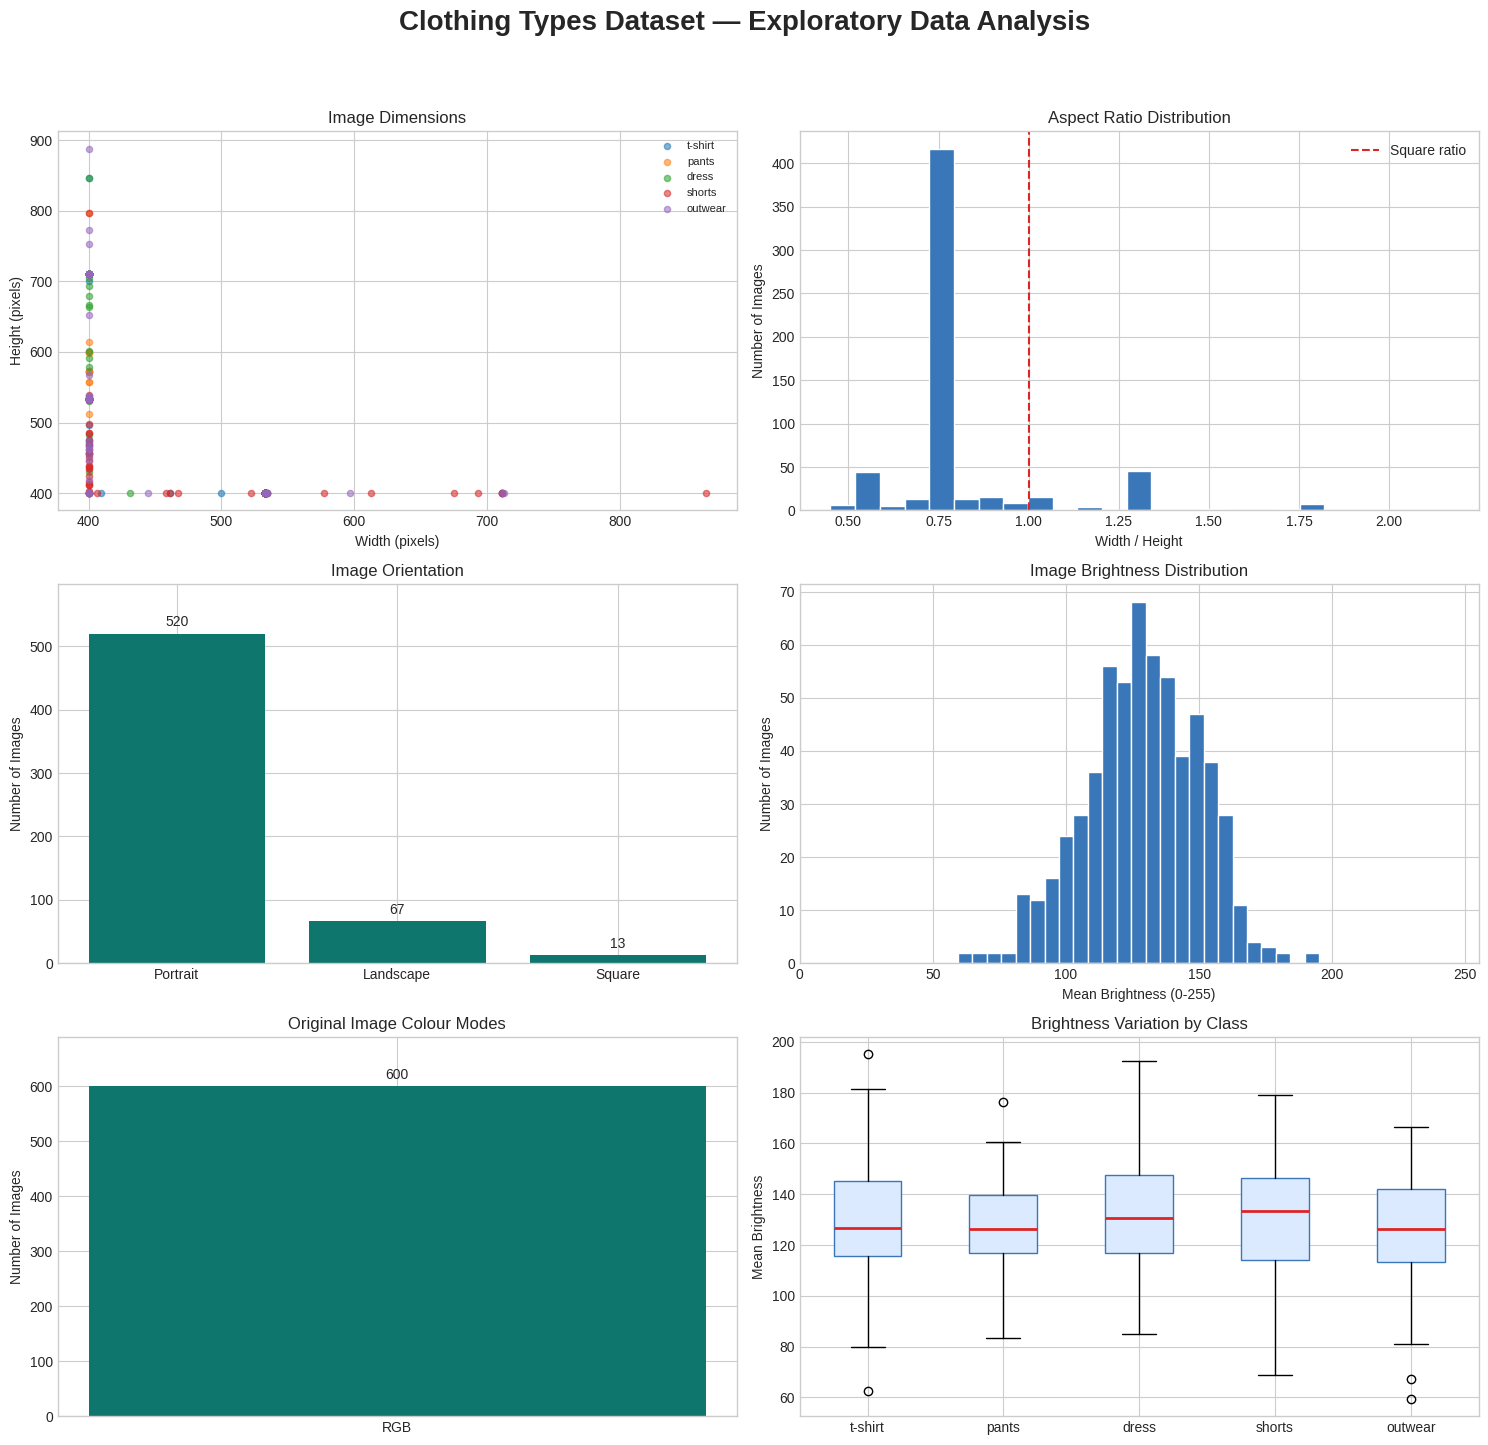

EDA dashboard saved successfully!
Location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/eda_dashboard.png


In [6]:
import matplotlib.pyplot as plt
# Professional visualization style
plt.style.use("seaborn-v0_8-whitegrid")
PRIMARY = "#3977B9"
SECONDARY = "#0F766E"
fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 15),
    facecolor="white"
)

# 1. Image dimensions
for label in CLASSES:

    subset = eda_df[eda_df["class"] == label]

    axes[0, 0].scatter(
        subset["width"],
        subset["height"],
        label=label,
        alpha=0.55,
        s=20
    )

axes[0, 0].set_title("Image Dimensions")
axes[0, 0].set_xlabel("Width (pixels)")
axes[0, 0].set_ylabel("Height (pixels)")
axes[0, 0].legend(fontsize=8)

# 2. Aspect ratio distribution
axes[0, 1].hist(
    eda_df["aspect_ratio"],
    bins=25,
    color=PRIMARY,
    edgecolor="white"
)

axes[0, 1].axvline(
    1,
    color="#DC2626",
    linestyle="--",
    label="Square ratio"
)

axes[0, 1].set_title("Aspect Ratio Distribution")
axes[0, 1].set_xlabel("Width / Height")
axes[0, 1].set_ylabel("Number of Images")
axes[0, 1].legend()

# 3. Image orientation
orientation_counts = (
    eda_df["orientation"].value_counts()
)

bars = axes[1, 0].bar(
    orientation_counts.index,
    orientation_counts.values,
    color=SECONDARY
)

axes[1, 0].bar_label(bars, padding=3)
axes[1, 0].set_ylim(
    0, orientation_counts.max() * 1.15
)
axes[1, 0].set_title("Image Orientation")
axes[1, 0].set_ylabel("Number of Images")

# 4. Brightness distribution
axes[1, 1].hist(
    eda_df["brightness"],
    bins=25,
    color=PRIMARY,
    edgecolor="white"
)

axes[1, 1].set_title("Image Brightness Distribution")
axes[1, 1].set_xlabel("Mean Brightness (0-255)")
axes[1, 1].set_ylabel("Number of Images")
axes[1, 1].set_xlim(0, 255)

# 5. Colour modes
mode_counts = eda_df["colour_mode"].value_counts()

bars = axes[2, 0].bar(
    mode_counts.index,
    mode_counts.values,
    color=SECONDARY
)

axes[2, 0].bar_label(bars, padding=3)
axes[2, 0].set_ylim(
    0, mode_counts.max() * 1.15
)
axes[2, 0].set_title("Original Image Colour Modes")
axes[2, 0].set_ylabel("Number of Images")

# 6. Brightness by class
brightness_groups = [
    eda_df.loc[
        eda_df["class"] == label,
        "brightness"
    ].values
    for label in CLASSES
]

axes[2, 1].boxplot(
    brightness_groups,
    tick_labels=CLASSES,
    patch_artist=True,
    boxprops={
        "facecolor": "#DBEAFE",
        "color": PRIMARY
    },
    medianprops={
        "color": "#DC2626",
        "linewidth": 2
    }
)

axes[2, 1].set_title("Brightness Variation by Class")
axes[2, 1].set_ylabel("Mean Brightness")

# Overall title
fig.suptitle(
    "Clothing Types Dataset — Exploratory Data Analysis",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[0, 0.02, 1, 0.95]
)

SAVE_PATH = PREPROCESSING_DIR / "eda_dashboard.png"

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("EDA dashboard saved successfully!")
print("Location:", SAVE_PATH)


## 3. Label Encoding

### 3.1 Clothing Class Mapping

Convert categorical clothing labels into numerical
class identifiers for supervised learning.

A fixed class mapping is maintained across all
subsequent machine learning experiments.


In [7]:

import pandas as pd
import json

# Fixed class-to-index mapping
CLASS_TO_ID = {
    "t-shirt": 0,
    "pants": 1,
    "dress": 2,
    "shorts": 3,
    "outwear": 4
}

# Reverse mapping for prediction interpretation
ID_TO_CLASS = {
    value: key
    for key, value in CLASS_TO_ID.items()
}

# Encode categorical labels
dataset_df["label"] = dataset_df["class"].map(
    CLASS_TO_ID
)

# Validate encoded labels
assert dataset_df["label"].notna().all(), (
    "Unknown class labels detected."
)

dataset_df["label"] = dataset_df["label"].astype(int)

NUM_CLASSES = len(CLASS_TO_ID)

print("LABEL ENCODING SUMMARY")
print("=" * 40)

print("Number of classes:", NUM_CLASSES)

mapping_df = pd.DataFrame({
    "Class": CLASS_TO_ID.keys(),
    "Label ID": CLASS_TO_ID.values()
})

display(mapping_df)

print("\nEncoded dataset preview:")

display(
    dataset_df[
        ["filename", "class", "label"]
    ].head(10)
)

print("\nLabel encoding completed successfully!")


LABEL ENCODING SUMMARY
Number of classes: 5


,Class,Label ID
0,t-shirt,0
1,pants,1
2,dress,2
3,shorts,3
4,outwear,4



Encoded dataset preview:


,filename,class,label
0,train_56df5a3e-235c-4ea8-b7e7-9244f09ae974.jpg,t-shirt,0
1,train_5da3e2de-dfef-43de-938f-89230c45cc95.jpg,t-shirt,0
2,test_ffa2be27-0798-488d-b9de-254de2226667.jpg,t-shirt,0
3,train_68fc2f45-6c5d-4a57-a3e7-2f6a72a4c486.jpg,t-shirt,0
4,train_1963940a-8c6c-4f2e-b746-1422413a6926.jpg,t-shirt,0
5,train_7c546852-22a8-468c-8c46-c1f4a13dec6b.jpg,t-shirt,0
6,train_911a104e-2ca1-4983-a732-7cff59fcbec1.jpg,t-shirt,0
7,train_07adbe68-f902-4819-8a74-420cf4745253.jpg,t-shirt,0
8,train_4d591b2d-59aa-4977-9f27-db69929cb9d8.jpg,t-shirt,0
9,validation_2324306f-d9a3-47b7-b648-8684b8aca35...,t-shirt,0



Label encoding completed successfully!



### 3.2 Label Encoding Validation and Export

Verify the consistency of numerical class labels
and preserve the class mapping for future model
training and evaluation.


In [8]:
# Verify label distribution
label_distribution = (
    dataset_df.groupby(["class", "label"])
    .size()
    .reset_index(name="Images")
    .sort_values("label")
)

display(label_distribution)

# Validate mapping consistency
assert len(dataset_df) == 600
assert dataset_df["label"].nunique() == 5

assert set(dataset_df["label"]) == set(range(5))

assert (
    dataset_df["label"].map(ID_TO_CLASS)
    == dataset_df["class"]
).all()

assert label_distribution["Images"].eq(120).all()

# Save class mapping
mapping_path = PREPROCESSING_DIR / "class_mapping.json"

with open(mapping_path, "w") as f:
    json.dump(CLASS_TO_ID, f, indent=4)

# Save encoded dataset manifest
encoded_path = (
    PREPROCESSING_DIR / "encoded_dataset_manifest.csv"
)

# Preserve relative paths for portability
dataset_df.drop(
    columns=["image_path", "file_exists"],
    errors="ignore"
).to_csv(encoded_path, index=False)

print("LABEL ENCODING VALIDATION: PASSED")

print("\nClass mapping saved:", mapping_path)
print("Encoded manifest saved:", encoded_path)


,class,label,Images
4,t-shirt,0,120
2,pants,1,120
0,dress,2,120
3,shorts,3,120
1,outwear,4,120


LABEL ENCODING VALIDATION: PASSED

Class mapping saved: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/class_mapping.json
Encoded manifest saved: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/encoded_dataset_manifest.csv



## 4. Stratified Data Splitting

### 4.1 Training, Validation and Test Set Creation

The cleaned dataset is divided into training,
validation, and test sets using a 70:15:15 ratio.

Stratified splitting preserves the class distribution
across all three subsets.

A fixed random seed of 42 is used to ensure
reproducibility.


In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 42

# Load encoded dataset
encoded_df = pd.read_csv(
    PREPROCESSING_DIR / "encoded_dataset_manifest.csv"
)

# Stable ordering for reproducibility
encoded_df = encoded_df.sort_values(
    "cleaned_relative_path"
).reset_index(drop=True)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    encoded_df,
    test_size=0.30,
    random_state=SEED,
    stratify=encoded_df["label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Assign split identifiers
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# Combine all split records
split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Display splitting results
print("STRATIFIED DATA SPLITTING")
print("=" * 45)

print("Total images:", len(split_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClass distribution:")

split_distribution = pd.crosstab(
    split_df["class"],
    split_df["split"]
).reindex(
    index=CLASSES,
    columns=["train", "validation", "test"],
    fill_value=0
)

split_distribution["Total"] = (
    split_distribution.sum(axis=1)
)

display(split_distribution)

print("\nStratified splitting completed!")


STRATIFIED DATA SPLITTING
Total images: 600
Training images: 420
Validation images: 90
Testing images: 90

Class distribution:


split,train,validation,test,Total
class,,,,
t-shirt,84,18,18,120
pants,84,18,18,120
dress,84,18,18,120
shorts,84,18,18,120
outwear,84,18,18,120



Stratified splitting completed!



### 4.2 Split Validation and Data Leakage Prevention

Validate the dataset sizes, class distributions,
label consistency, unique image paths, and image hashes.

Ensure that training, validation, and test sets
do not contain overlapping image files.


In [10]:
from itertools import combinations

expected_sizes = {
    "train": 420,
    "validation": 90,
    "test": 90
}

expected_per_class = {
    "train": 84,
    "validation": 18,
    "test": 18
}

split_sets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# Check overlap between every pair of sets
path_overlap = 0
hash_overlap = 0

for a, b in combinations(split_sets.keys(), 2):

    first = split_sets[a]
    second = split_sets[b]

    path_overlap += len(
        set(first["cleaned_relative_path"]) &
        set(second["cleaned_relative_path"])
    )

    hash_overlap += len(
        set(first["sha256"]) &
        set(second["sha256"])
    )

# Define validation checks
checks = {
    "All 600 images retained":
        len(split_df) == len(encoded_df) == 600,

    "All original image paths retained":
        set(split_df["cleaned_relative_path"]) ==
        set(encoded_df["cleaned_relative_path"]),

    "Correct split sizes":
        all(
            len(split_sets[s]) == expected_sizes[s]
            for s in split_sets
        ),

    "All five classes in every split":
        all(
            set(df["class"]) == set(CLASSES)
            for df in split_sets.values()
        ),

    "Correct stratified distribution":
        all(
            split_distribution[s].eq(
                expected_per_class[s]
            ).all()
            for s in split_sets
        ),

    "Minimum 10 test images per class":
        split_distribution["test"].ge(10).all(),

    "No duplicate image paths":
        split_df["cleaned_relative_path"].is_unique,

    "No missing or duplicate image hashes":
        split_df["sha256"].notna().all()
        and split_df["sha256"].is_unique,

    "No path overlap between sets":
        path_overlap == 0,

    "No hash overlap between sets":
        hash_overlap == 0
}

# Generate validation report
split_validation = pd.DataFrame([
    {
        "Validation Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in checks.items()
])

display(split_validation)

print("Image path overlap:", path_overlap)
print("Image hash overlap:", hash_overlap)

SPLIT_VALIDATED = all(checks.values())

if SPLIT_VALIDATED:
    print("\nDATA SPLIT VALIDATION: PASSED")
else:
    raise ValueError(
        "Data split validation failed."
    )


,Validation Check,Status
0,All 600 images retained,PASS
1,All original image paths retained,PASS
2,Correct split sizes,PASS
3,All five classes in every split,PASS
4,Correct stratified distribution,PASS
5,Minimum 10 test images per class,PASS
6,No duplicate image paths,PASS
7,No missing or duplicate image hashes,PASS
8,No path overlap between sets,PASS
9,No hash overlap between sets,PASS


Image path overlap: 0
Image hash overlap: 0

DATA SPLIT VALIDATION: PASSED



### 4.3 Dataset Split Export

Save the validated dataset split manifests
for reproducible machine learning experiments.

The same fixed dataset partitions will be
used throughout subsequent model development.


In [11]:

import json

assert SPLIT_VALIDATED, "Validate the splits first."

# Save individual split manifests
for name, df in split_sets.items():

    save_path = PREPROCESSING_DIR / f"{name}_manifest.csv"

    df.to_csv(
        save_path,
        index=False
    )

    print(f"{name}: {len(df)} records saved")

# Save combined manifest
split_df.to_csv(
    PREPROCESSING_DIR / "split_dataset_manifest.csv",
    index=False
)

# Save distribution and validation reports
split_distribution.to_csv(
    PREPROCESSING_DIR / "split_distribution.csv"
)

split_validation.to_csv(
    PREPROCESSING_DIR / "split_validation.csv",
    index=False
)

# Save splitting configuration
split_config = {
    "random_seed": SEED,
    "stratified": True,
    "train_ratio": 0.70,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,
    "total_images": len(split_df),
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "testing_images": len(test_df)
}

with open(
    PREPROCESSING_DIR / "split_config.json",
    "w"
) as f:

    json.dump(split_config, f, indent=4)

print("\nDataset splits exported successfully!")
print("Location:", PREPROCESSING_DIR)


train: 420 records saved
validation: 90 records saved
test: 90 records saved

Dataset splits exported successfully!
Location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing



### 4.4 Dataset Split Distribution Visualization

Visualize the number of training, validation,
and test images across the five clothing classes.


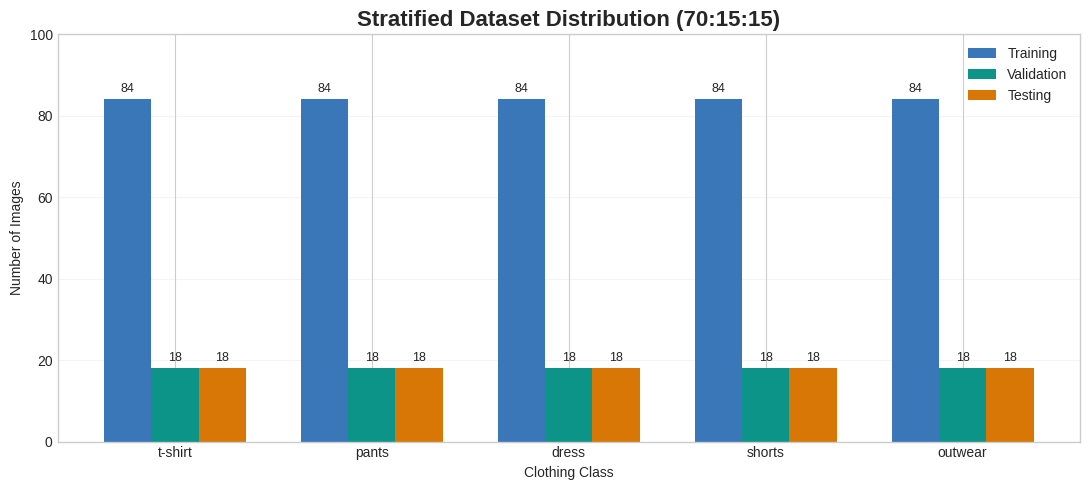

Split visualization saved successfully!


In [12]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(CLASSES))
width = 0.24

fig, ax = plt.subplots(
    figsize=(11, 5),
    facecolor="white"
)

split_styles = [
    ("train", "Training", "#3977B9"),
    ("validation", "Validation", "#0D9488"),
    ("test", "Testing", "#D97706")
]

for i, (key, name, color) in enumerate(split_styles):

    bars = ax.bar(
        x + (i - 1) * width,
        split_distribution[key],
        width,
        label=name,
        color=color
    )

    ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title(
    "Stratified Dataset Distribution (70:15:15)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Clothing Class")
ax.set_ylabel("Number of Images")

ax.set_xticks(x)
ax.set_xticklabels(CLASSES)

ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    PREPROCESSING_DIR / "split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Split visualization saved successfully!")



## 5. Image Resizing and Normalization

### 5.1 Comparison of Image Resizing Methods

Compare direct resizing, centre cropping, and
aspect-ratio-preserving resizing with padding.

The selected method aims to preserve important
clothing characteristics without introducing
unnecessary shape distortion or information loss.


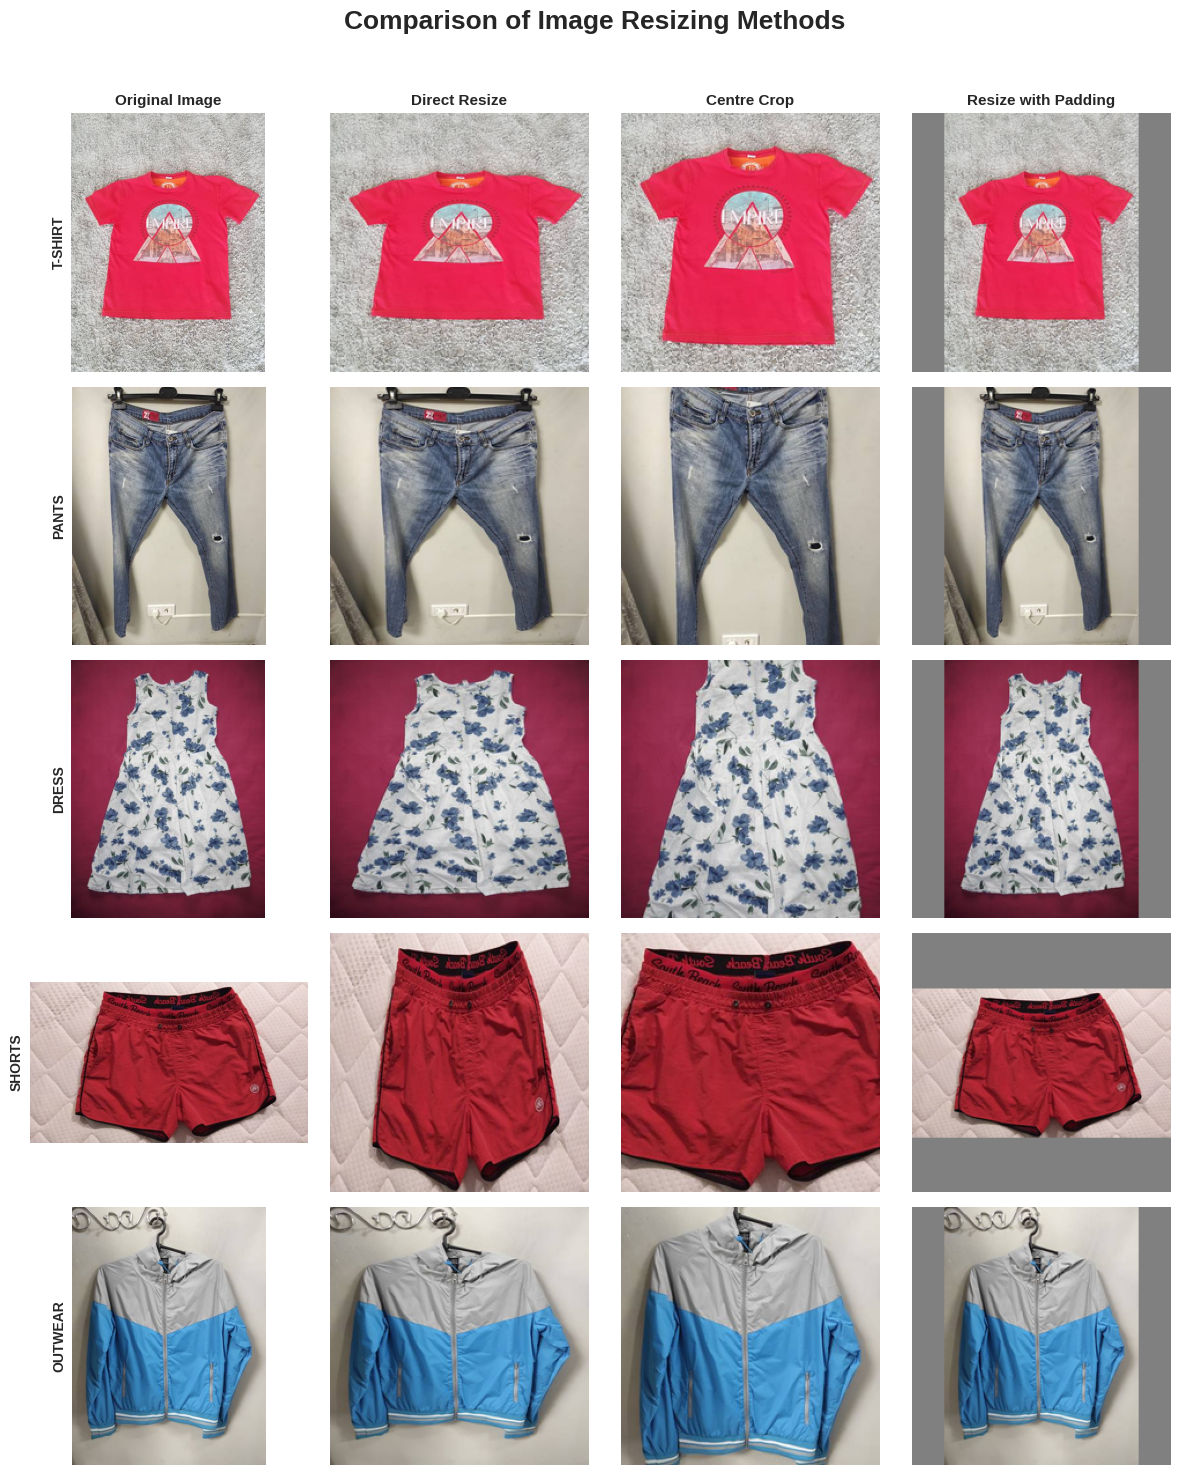

Resizing comparison saved successfully!


In [13]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

IMAGE_SIZE = (224, 224)
PADDING_COLOR = (128, 128, 128)
SEED = 42

# Load the fixed dataset partitions
split_df = pd.read_csv(
    PREPROCESSING_DIR / "split_dataset_manifest.csv"
)

# Use training images for method comparison
training_samples = split_df[
    split_df["split"] == "train"
]

comparison_classes = [
    "t-shirt",
    "pants",
    "dress",
    "shorts",
    "outwear"
]

fig, axes = plt.subplots(
    5, 4,
    figsize=(12, 15),
    facecolor="white"
)

methods = [
    "Original Image",
    "Direct Resize",
    "Centre Crop",
    "Resize with Padding"
]

for i, label in enumerate(comparison_classes):

    sample = training_samples[
        training_samples["class"] == label
    ].sample(n=1, random_state=SEED).iloc[0]

    path = CLEAN_DIR / sample["cleaned_relative_path"]

    with Image.open(path) as img:

        original = ImageOps.exif_transpose(img)
        original = original.convert("RGB")

    # Method 1: Direct resize
    stretched = original.resize(
        IMAGE_SIZE,
        Image.Resampling.LANCZOS
    )

    # Method 2: Centre crop
    cropped = ImageOps.fit(
        original,
        IMAGE_SIZE,
        method=Image.Resampling.LANCZOS
    )

    # Method 3: Preserve aspect ratio
    padded = ImageOps.pad(
        original,
        IMAGE_SIZE,
        method=Image.Resampling.LANCZOS,
        color=PADDING_COLOR
    )
    images = [
        original,
        stretched,
        cropped,
        padded
    ]
    for j, image in enumerate(images):

        ax = axes[i, j]
        ax.imshow(image)
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if i == 0:
            ax.set_title(
                methods[j],
                fontsize=11,
                fontweight="bold"
            )

        if j == 0:
            ax.set_ylabel(
                label.upper(),
                fontsize=10,
                fontweight="bold"
            )

fig.suptitle(
    "Comparison of Image Resizing Methods",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    PREPROCESSING_DIR / "resize_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Resizing comparison saved successfully!")



### 5.2 Aspect-Ratio-Preserving Image Resizing

Resize all images to 224 × 224 pixels while
preserving their original aspect ratios.

Neutral grey padding is applied where necessary.
All images are converted to RGB and saved in PNG
format within their assigned dataset partitions.

The original cleaned dataset remains unchanged.


In [14]:

from pathlib import Path
from PIL import Image, ImageOps
from io import BytesIO
from tqdm.auto import tqdm

import hashlib
import pandas as pd
import numpy as np

IMAGE_SIZE = (224, 224)
PADDING_COLOR = (128, 128, 128)

processed_df = split_df.copy()

# Construct output paths
processed_df["processed_relative_path"] = (
    processed_df.apply(
        lambda row: (
            f"{row['split']}/"
            f"{row['class']}/"
            f"{Path(row['filename']).stem}.png"
        ),
        axis=1
    )
)

# Prevent filename collisions
assert processed_df[
    "processed_relative_path"
].is_unique

expected_paths = set(
    processed_df["processed_relative_path"]
)

existing_paths = {
    p.relative_to(PROCESSED_DIR).as_posix()
    for p in PROCESSED_DIR.rglob("*")
    if p.is_file()
}

if existing_paths - expected_paths:
    raise ValueError(
        "Unexpected files found in processed_dataset."
    )

processed_hashes = []

# Process the fixed dataset partitions
for _, row in tqdm(
    processed_df.iterrows(),
    total=len(processed_df),
    desc="Processing images"
):

    source = CLEAN_DIR / row["cleaned_relative_path"]

    destination = (
        PROCESSED_DIR / row["processed_relative_path"]
    )

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Verify original file integrity
    image_bytes = source.read_bytes()

    original_hash = hashlib.sha256(
        image_bytes
    ).hexdigest()

    if original_hash != row["sha256"]:
        raise ValueError(
            f"Original image hash mismatch: {source}"
        )

    # Resize while preserving aspect ratio
    with Image.open(BytesIO(image_bytes)) as img:

        img = ImageOps.exif_transpose(img)
        img = img.convert("RGB")

        processed = ImageOps.pad(
            img,
            IMAGE_SIZE,
            method=Image.Resampling.LANCZOS,
            color=PADDING_COLOR
        )

        # Save resized image
        processed.save(destination, format="PNG")

        # Hash processed pixel data
        pixel_hash = hashlib.sha256(
            processed.tobytes()
        ).hexdigest()

        processed_hashes.append(pixel_hash)

# Update processed dataset metadata
processed_df["processed_pixel_sha256"] = processed_hashes
processed_df["processed_width"] = IMAGE_SIZE[0]
processed_df["processed_height"] = IMAGE_SIZE[1]
processed_df["processed_channels"] = 3

# Detect identical processed images across splits
cross_split_duplicates = (
    processed_df.groupby("processed_pixel_sha256")["split"]
    .nunique()
    .gt(1)
)

assert not cross_split_duplicates.any(), (
    "Identical processed images detected across splits."
)

# Verify processed file availability
actual_paths = {
    p.relative_to(PROCESSED_DIR).as_posix()
    for p in PROCESSED_DIR.rglob("*")
    if p.is_file()
}

assert actual_paths == expected_paths

# Save processed dataset manifest
processed_df.to_csv(
    PREPROCESSING_DIR / "processed_dataset_manifest.csv",
    index=False
)

print("\nIMAGE RESIZING SUMMARY")
print("=" * 45)

print("Total processed images:", len(processed_df))
print("Image size:", IMAGE_SIZE)
print("Colour channels: RGB")
print("Storage format: PNG")

display(
    pd.crosstab(
        processed_df["class"],
        processed_df["split"]
    ).reindex(
        index=CLASSES,
        columns=["train", "validation", "test"]
    )
)

print("\nImage resizing completed successfully!")
print("Original cleaned dataset remains unchanged.")


Processing images:   0%|          | 0/600 [00:00<?, ?it/s]


IMAGE RESIZING SUMMARY
Total processed images: 600
Image size: (224, 224)
Colour channels: RGB
Storage format: PNG


split,train,validation,test
class,,,
t-shirt,84,18,18
pants,84,18,18
dress,84,18,18
shorts,84,18,18
outwear,84,18,18



Image resizing completed successfully!
Original cleaned dataset remains unchanged.



### 5.3 Pixel Normalization

Convert image pixel values from the original
range of [0, 255] to the range [-1, 1] using
MobileNetV2-compatible preprocessing.

Normalized arrays use the float32 data type.

Normalization is applied during model input
preparation rather than permanently modifying
the stored image files.


,Property,Before Normalization,After Normalization
0,Shape,"(224, 224, 3)","(224, 224, 3)"
1,Data type,uint8,float32
2,Minimum value,0.0,-1.0
3,Maximum value,230.0,0.803922
4,Mean value,122.096,-0.0424


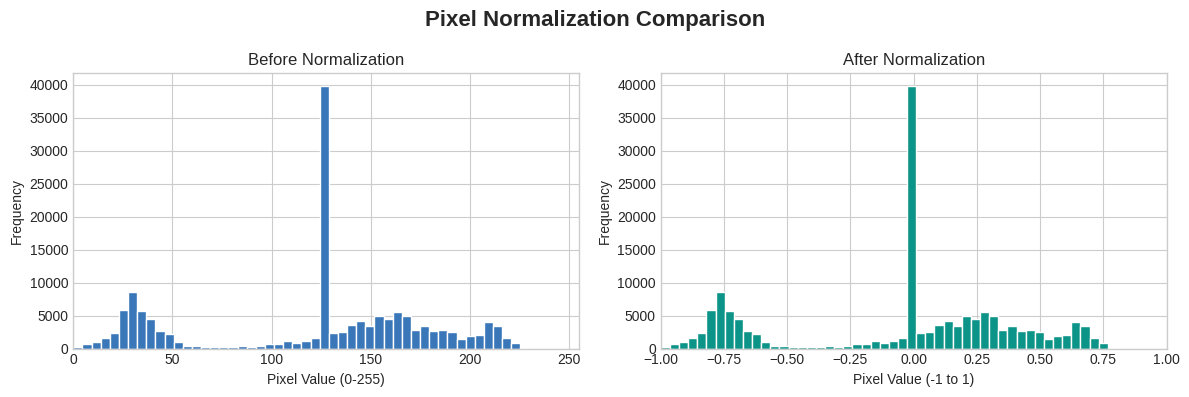

NORMALIZATION VALIDATION: PASSED


In [15]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def normalize_image(image):

    image = np.asarray(
        image,
        dtype=np.float32
    )

    return (
        image / np.float32(127.5)
    ) - np.float32(1.0)

# Select a sample from the training set
sample = processed_df[
    processed_df["split"] == "train"
].sample(n=1, random_state=SEED).iloc[0]

sample_path = (
    PROCESSED_DIR / sample["processed_relative_path"]
)

with Image.open(sample_path) as img:

    original_array = np.asarray(
        img.convert("RGB"),
        dtype=np.uint8
    )

normalized_array = normalize_image(
    original_array
)

# Validate normalized image
assert normalized_array.shape == (224, 224, 3)
assert normalized_array.dtype == np.float32
assert np.isfinite(normalized_array).all()

assert normalized_array.min() >= -1.0
assert normalized_array.max() <= 1.0

# Display numerical comparison
comparison_df = pd.DataFrame({
    "Property": [
        "Shape",
        "Data type",
        "Minimum value",
        "Maximum value",
        "Mean value"
    ],
    "Before Normalization": [
        str(original_array.shape),
        str(original_array.dtype),
        float(original_array.min()),
        float(original_array.max()),
        round(float(original_array.mean()), 4)
    ],
    "After Normalization": [
        str(normalized_array.shape),
        str(normalized_array.dtype),
        float(normalized_array.min()),
        float(normalized_array.max()),
        round(float(normalized_array.mean()), 4)
    ]
})

display(comparison_df)

# Compare pixel distributions
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    facecolor="white"
)

axes[0].hist(
    original_array.flatten(),
    bins=50,
    color="#3977B9",
    edgecolor="white"
)

axes[0].set_title("Before Normalization")
axes[0].set_xlabel("Pixel Value (0-255)")
axes[0].set_ylabel("Frequency")
axes[0].set_xlim(0, 255)

axes[1].hist(
    normalized_array.flatten(),
    bins=50,
    color="#0D9488",
    edgecolor="white"
)

axes[1].set_title("After Normalization")
axes[1].set_xlabel("Pixel Value (-1 to 1)")
axes[1].set_ylabel("Frequency")
axes[1].set_xlim(-1, 1)

fig.suptitle(
    "Pixel Normalization Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PREPROCESSING_DIR / "normalization_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("NORMALIZATION VALIDATION: PASSED")



### 5.4 Image Preprocessing Configuration

Save the selected image resizing, colour conversion,
padding, storage, and normalization parameters
for reproducible machine learning experiments.


In [16]:
import json

preprocessing_config = {
    "total_images": len(processed_df),
    "number_of_classes": 5,
    "image_width": IMAGE_SIZE[0],
    "image_height": IMAGE_SIZE[1],
    "channels": 3,
    "colour_mode": "RGB",
    "resize_method": "aspect_ratio_preserving_padding",
    "interpolation": "LANCZOS",
    "padding_colour": list(PADDING_COLOR),
    "storage_format": "PNG",
    "stored_dtype": "uint8",
    "model_input_dtype": "float32",
    "normalization": {
        "method": "MobileNetV2-compatible",
        "formula": "x / 127.5 - 1",
        "input_range": [0, 255],
        "output_range": [-1, 1],
        "applied_at": "model_input_loading"
    },
    "random_seed": SEED,
    "augmentation_applied": False
}

config_path = (
    PREPROCESSING_DIR / "preprocessing_config.json"
)

with open(config_path, "w") as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

print("Preprocessing configuration saved!")
print("Location:", config_path)

display(preprocessing_config)


Preprocessing configuration saved!
Location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/preprocessing_config.json


{'total_images': 600,
 'number_of_classes': 5,
 'image_width': 224,
 'image_height': 224,
 'channels': 3,
 'colour_mode': 'RGB',
 'resize_method': 'aspect_ratio_preserving_padding',
 'interpolation': 'LANCZOS',
 'padding_colour': [128, 128, 128],
 'storage_format': 'PNG',
 'stored_dtype': 'uint8',
 'model_input_dtype': 'float32',
 'normalization': {'method': 'MobileNetV2-compatible',
  'formula': 'x / 127.5 - 1',
  'input_range': [0, 255],
  'output_range': [-1, 1],
  'applied_at': 'model_input_loading'},
 'random_seed': 42,
 'augmentation_applied': False}


## 6. Data Augmentation

### 6.1 Training Data Augmentation Pipeline

Apply controlled online data augmentation to
increase training image diversity and reduce
the risk of overfitting.

The transformations include horizontal flipping,
small rotations, brightness adjustment, and
contrast adjustment.

Augmentation is restricted to training data.
Validation and test images remain unchanged.


In [17]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import json

SEED = 42

# Load processed dataset manifest
processed_df = pd.read_csv(
    PREPROCESSING_DIR / "processed_dataset_manifest.csv"
)

# Augmentation configuration
augmentation_config = {
    "method": "online",
    "enabled_for": ["train"],
    "horizontal_flip": True,
    "rotation_degrees": 5,
    "brightness_factor": 0.06,
    "contrast_factor": 0.10,
    "fill_mode": "constant",
    "fill_value": 128,
    "random_seed": SEED
}

# Build reusable augmentation pipeline
def build_augmentation():

    return keras.Sequential([

        layers.RandomFlip(
            mode="horizontal",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=5 / 360,
            fill_mode="constant",
            fill_value=128.0,
            interpolation="bilinear",
            seed=SEED + 1
        ),

        layers.RandomBrightness(
            factor=0.06,
            value_range=(0, 255),
            seed=SEED + 2
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED + 3
        )

    ], name="training_augmentation")

data_augmentation = build_augmentation()

print("DATA AUGMENTATION CONFIGURATION")
print("=" * 45)

print("TensorFlow version:", tf.__version__)
print("Augmentation method: Online")
print("Horizontal flip: Enabled")
print("Random rotation: +/- 5 degrees")
print("Brightness adjustment: +/- 6% of pixel range")
print("Contrast adjustment: +/- 10%")
print("Applied to: Training set only")

print("\nAugmentation pipeline initialized!")


DATA AUGMENTATION CONFIGURATION
TensorFlow version: 2.21.0
Augmentation method: Online
Horizontal flip: Enabled
Random rotation: +/- 5 degrees
Brightness adjustment: +/- 6% of pixel range
Contrast adjustment: +/- 10%
Applied to: Training set only

Augmentation pipeline initialized!



### 6.2 Augmentation Visualization

Visualize original training images alongside
randomly augmented variations.

The comparison helps verify that transformations
preserve the essential visual characteristics
of each clothing category.


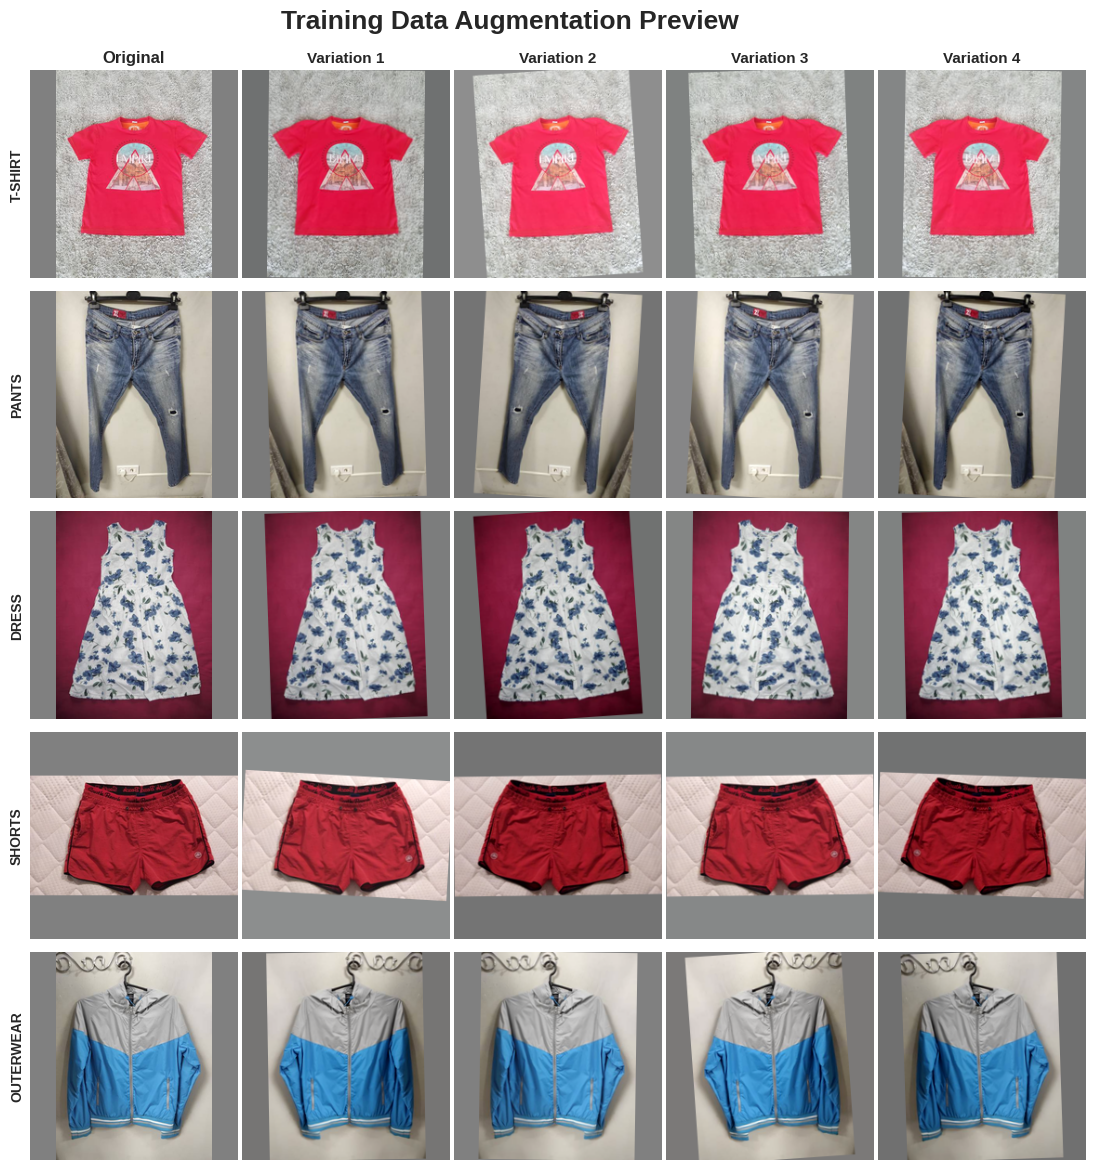

Augmentation preview generated successfully!
Saved to: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/augmentation_preview.png


In [18]:

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

CLASSES = [
    "t-shirt",
    "pants",
    "dress",
    "shorts",
    "outwear"
]

DISPLAY_NAMES = {
    "t-shirt": "T-SHIRT",
    "pants": "PANTS",
    "dress": "DRESS",
    "shorts": "SHORTS",
    "outwear": "OUTERWEAR"
}

# Only use training images
training_df = processed_df[
    processed_df["split"] == "train"
].copy()

assert len(training_df) == 420

# Separate augmentation instance for preview
preview_augmentation = build_augmentation()

NUM_VARIATIONS = 4

fig, axes = plt.subplots(
    len(CLASSES),
    NUM_VARIATIONS + 1,
    figsize=(12, 12),
    facecolor="white"
)

for row, label in enumerate(CLASSES):

    # Select one reproducible training sample
    sample = training_df[
        training_df["class"] == label
    ].sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    image_path = (
        PROCESSED_DIR /
        sample["processed_relative_path"]
    )

    with Image.open(image_path) as img:

        original = np.asarray(
            img.convert("RGB"),
            dtype=np.float32
        )

    assert original.shape == (224, 224, 3)

    # Original image
    axes[row, 0].imshow(
        original.astype(np.uint8)
    )

    axes[row, 0].set_ylabel(
        DISPLAY_NAMES[label],
        fontsize=10,
        fontweight="bold"
    )

    # Generate random variations
    for col in range(1, NUM_VARIATIONS + 1):

        augmented = preview_augmentation(
            original[None, ...],
            training=True
        )[0].numpy()

        augmented = np.clip(
            augmented, 0, 255
        )

        axes[row, col].imshow(
            augmented.astype(np.uint8)
        )

    # Remove axis decoration
    for ax in axes[row]:

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

# Column titles
axes[0, 0].set_title(
    "Original",
    fontweight="bold"
)

for col in range(1, NUM_VARIATIONS + 1):

    axes[0, col].set_title(
        f"Variation {col}",
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "Training Data Augmentation Preview",
    fontsize=19,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.93,
    bottom=0.02,
    wspace=0.02,
    hspace=0.05
)

SAVE_PATH = (
    PREPROCESSING_DIR /
    "augmentation_preview.png"
)

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Augmentation preview generated successfully!")
print("Saved to:", SAVE_PATH)



### 6.3 Augmentation Validation

Validate augmented image dimensions, numerical
values, and inference behaviour.

Ensure that augmentation is disabled during
validation and testing.


In [19]:
# Select training images for validation
sample_df = training_df.sample(
    n=20,
    random_state=SEED
)

sample_images = []

for _, row in sample_df.iterrows():

    path = (
        PROCESSED_DIR /
        row["processed_relative_path"]
    )

    with Image.open(path) as img:

        sample_images.append(
            np.asarray(
                img.convert("RGB"),
                dtype=np.float32
            )
        )

original_batch = np.stack(sample_images)

# Separate instance for validation
validation_augmentation = build_augmentation()

# Apply random training transformations
augmented_batch = validation_augmentation(
    original_batch,
    training=True
).numpy()

# Disable transformations during inference
inference_batch = validation_augmentation(
    original_batch,
    training=False
).numpy()

# Enforce valid pixel range
clipped_batch = np.clip(
    augmented_batch, 0, 255
)

# Validate normalization after augmentation
normalized_batch = (
    clipped_batch.astype(np.float32) / 127.5
) - 1.0

# Validation checks
checks = {
    "Training samples only":
        sample_df["split"].eq("train").all(),

    "Correct image dimensions":
        augmented_batch.shape == (20, 224, 224, 3),

    "Valid numerical values":
        np.isfinite(augmented_batch).all(),

    "Valid pixel range after clipping":
        clipped_batch.min() >= 0
        and clipped_batch.max() <= 255,

    "Augmentation produces variations":
        not np.array_equal(
            original_batch,
            augmented_batch
        ),

    "No augmentation during inference":
        np.allclose(
            original_batch,
            inference_batch
        ),

    "Correct normalized pixel range":
        normalized_batch.min() >= -1.0
        and normalized_batch.max() <= 1.0
}

augmentation_validation = pd.DataFrame([
    {
        "Validation Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in checks.items()
])

display(augmentation_validation)

AUGMENTATION_VALIDATED = all(checks.values())

assert AUGMENTATION_VALIDATED, (
    "Augmentation validation failed."
)

augmentation_validation.to_csv(
    PREPROCESSING_DIR /
    "augmentation_validation.csv",
    index=False
)

print("\nAUGMENTATION VALIDATION: PASSED")

print("Original batch:", original_batch.shape)
print("Augmented batch:", augmented_batch.shape)

print(
    "Normalized range:",
    float(normalized_batch.min()),
    "to",
    float(normalized_batch.max())
)


,Validation Check,Status
0,Training samples only,PASS
1,Correct image dimensions,PASS
2,Valid numerical values,PASS
3,Valid pixel range after clipping,PASS
4,Augmentation produces variations,PASS
5,No augmentation during inference,PASS
6,Correct normalized pixel range,PASS



AUGMENTATION VALIDATION: PASSED
Original batch: (20, 224, 224, 3)
Augmented batch: (20, 224, 224, 3)
Normalized range: -1.0 to 1.0



### 6.4 Augmentation Configuration Export

Save the augmentation parameters and pipeline
architecture for reproducible model development.

Augmentation is performed dynamically during
training without creating additional stored images.


In [20]:

import json

assert AUGMENTATION_VALIDATED

# Save augmentation settings
augmentation_config["tensorflow_version"] = (
    tf.__version__
)

with open(
    PREPROCESSING_DIR / "augmentation_config.json",
    "w"
) as f:

    json.dump(
        augmentation_config,
        f,
        indent=4
    )

# Save reusable Keras pipeline architecture
with open(
    PREPROCESSING_DIR / "augmentation_pipeline.json",
    "w"
) as f:

    f.write(data_augmentation.to_json())

# Update existing preprocessing configuration
config_path = (
    PREPROCESSING_DIR /
    "preprocessing_config.json"
)

with open(config_path, "r") as f:
    preprocessing_config = json.load(f)

preprocessing_config["augmentation"] = (
    augmentation_config
)

preprocessing_config["augmentation_configured"] = True

# No permanent augmentation of stored images
preprocessing_config["augmentation_applied"] = False

preprocessing_config["augmentation_stage"] = (
    "During model training only"
)

with open(config_path, "w") as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

print("Augmentation configuration saved!")
print("Reusable pipeline architecture saved.")
print("Preprocessing configuration updated.")

print("\nStored training images: 420")
print("Stored validation images: 90")
print("Stored testing images: 90")
print("Total stored images: 600")

print("\nOriginal image files remain unchanged.")


Augmentation configuration saved!
Reusable pipeline architecture saved.
Preprocessing configuration updated.

Stored training images: 420
Stored validation images: 90
Stored testing images: 90
Total stored images: 600

Original image files remain unchanged.



## 7. Final Preprocessing Validation

### 7.1 Processed Image Integrity Validation

Validate all processed images to ensure consistent
dimensions, RGB colour channels, pixel data integrity,
and correct normalization.

The validation process does not modify the dataset
or apply data augmentation.


In [21]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import pandas as pd
import numpy as np
import hashlib
import json

# Project configuration
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SAIA2113_Clothing_Types_V2"
)

PROCESSED_DIR = PROJECT_ROOT / "processed_dataset"
PREPROCESSING_DIR = (
    PROJECT_ROOT / "reports" / "preprocessing"
)

CLASSES = ["t-shirt", "pants", "dress", "shorts", "outwear"]

# Load processed dataset manifest
processed_df = pd.read_csv(
    PREPROCESSING_DIR / "processed_dataset_manifest.csv"
)

validation_records = []

# Validate every processed image
for _, row in tqdm(
    processed_df.iterrows(),
    total=len(processed_df),
    desc="Validating processed images"
):

    path = (
        PROCESSED_DIR /
        row["processed_relative_path"]
    )

    record = {
        "filename": row["filename"],
        "class": row["class"],
        "label": row["label"],
        "split": row["split"],
        "relative_path": row["processed_relative_path"],
        "file_exists": path.is_file(),
        "readable": False,
        "correct_format": False,
        "correct_dimensions": False,
        "correct_colour_mode": False,
        "correct_dtype": False,
        "pixel_hash_match": False,
        "normalization_valid": False,
        "actual_pixel_sha256": "",
        "error": ""
    }

    if path.is_file():

        try:

            with Image.open(path) as img:

                img.load()

                record["readable"] = True

                record["correct_format"] = (
                    img.format == "PNG"
                )

                record["correct_dimensions"] = (
                    img.size == (224, 224)
                )

                record["correct_colour_mode"] = (
                    img.mode == "RGB"
                )

                array = np.asarray(img)

            record["correct_dtype"] = (
                array.dtype == np.uint8
            )

            # Verify actual image pixel integrity
            pixel_hash = hashlib.sha256(
                array.tobytes()
            ).hexdigest()

            record["actual_pixel_sha256"] = pixel_hash

            record["pixel_hash_match"] = (
                pixel_hash ==
                row["processed_pixel_sha256"]
            )

            # Verify MobileNetV2 normalization
            normalized = (
                array.astype(np.float32)
                / np.float32(127.5)
                - np.float32(1.0)
            )

            record["normalization_valid"] = bool(
                normalized.shape == (224, 224, 3)
                and normalized.dtype == np.float32
                and np.isfinite(normalized).all()
                and normalized.min() >= -1.0
                and normalized.max() <= 1.0
            )

        except Exception as error:

            record["error"] = str(error)

    else:

        record["error"] = "Image file not found"

    validation_records.append(record)

# Create validation DataFrame
final_image_validation = pd.DataFrame(
    validation_records
)

# Determine overall image status
image_checks = [
    "file_exists",
    "readable",
    "correct_format",
    "correct_dimensions",
    "correct_colour_mode",
    "correct_dtype",
    "pixel_hash_match",
    "normalization_valid"
]

final_image_validation["status"] = np.where(
    final_image_validation[image_checks].all(axis=1),
    "PASS",
    "FAIL"
)

# Save individual image validation results
final_image_validation.to_csv(
    PREPROCESSING_DIR /
    "final_processed_image_validation.csv",
    index=False
)

# Display results
print("PROCESSED IMAGE VALIDATION")
print("=" * 45)

print("Total images checked:", len(final_image_validation))

print(
    "Passed:",
    final_image_validation["status"].eq("PASS").sum()
)

print(
    "Failed:",
    final_image_validation["status"].eq("FAIL").sum()
)

display(
    pd.crosstab(
        final_image_validation["class"],
        final_image_validation["status"]
    )
)

failed_images = final_image_validation[
    final_image_validation["status"] == "FAIL"
]

if not failed_images.empty:
    display(failed_images)
    raise ValueError("Some processed images failed validation.")

print("\nAll processed images passed validation!")


Validating processed images:   0%|          | 0/600 [00:00<?, ?it/s]

PROCESSED IMAGE VALIDATION
Total images checked: 600
Passed: 600
Failed: 0


status,PASS
class,
dress,120
outwear,120
pants,120
shorts,120
t-shirt,120



All processed images passed validation!



### 7.2 Final Dataset Consistency Validation

Verify dataset partitions, class distributions,
numerical labels, image uniqueness, and
preprocessing configurations.

Ensure that the processed dataset maintains the
original validated dataset assignments and that
augmentation is configured for training only.


In [22]:

# Load reference manifests and configurations
split_manifest = pd.read_csv(
    PREPROCESSING_DIR / "split_dataset_manifest.csv"
)

with open(
    PREPROCESSING_DIR / "class_mapping.json"
) as f:
    class_mapping = json.load(f)

with open(
    PREPROCESSING_DIR / "preprocessing_config.json"
) as f:
    config = json.load(f)

with open(
    PREPROCESSING_DIR / "augmentation_config.json"
) as f:
    aug_config = json.load(f)

with open(
    PREPROCESSING_DIR / "split_config.json"
) as f:
    split_config = json.load(f)

# Check actual files against manifest
actual_files = {
    p.relative_to(PROCESSED_DIR).as_posix()
    for p in PROCESSED_DIR.rglob("*")
    if p.is_file()
}

expected_files = set(
    processed_df["processed_relative_path"]
)

# Class distribution
final_distribution = pd.crosstab(
    processed_df["class"],
    processed_df["split"]
).reindex(
    index=CLASSES,
    columns=["train", "validation", "test"],
    fill_value=0
)

# Compare original and processed assignments
comparison_columns = [
    "cleaned_relative_path",
    "class",
    "label",
    "split",
    "sha256"
]

original_assignments = (
    split_manifest[comparison_columns]
    .sort_values("cleaned_relative_path")
    .reset_index(drop=True)
)

processed_assignments = (
    processed_df[comparison_columns]
    .sort_values("cleaned_relative_path")
    .reset_index(drop=True)
)

# Check processed pixel overlap across splits
pixel_overlap = (
    final_image_validation
    .groupby("actual_pixel_sha256")["split"]
    .nunique()
    .gt(1)
    .sum()
)

# Check original image hash overlap
original_hash_overlap = (
    processed_df.groupby("sha256")["split"]
    .nunique()
    .gt(1)
    .sum()
)

# Check expected folder structure
expected_structure = processed_df.apply(
    lambda row: (
        f"{row['split']}/"
        f"{row['class']}/"
        f"{Path(row['filename']).stem}.png"
    ),
    axis=1
)

# Final validation checks
final_checks = {
    "Total dataset contains 600 images":
        len(processed_df) == 600,

    "Exactly five clothing classes":
        set(processed_df["class"]) == set(CLASSES),

    "Training set contains 420 images":
        processed_df["split"].eq("train").sum() == 420,

    "Validation set contains 90 images":
        processed_df["split"].eq("validation").sum() == 90,

    "Test set contains 90 images":
        processed_df["split"].eq("test").sum() == 90,

    "Balanced stratified distribution":
        final_distribution["train"].eq(84).all()
        and final_distribution["validation"].eq(18).all()
        and final_distribution["test"].eq(18).all(),

    "Correct numerical class mapping":
        class_mapping == dict(zip(CLASSES, range(5)))
        and processed_df["class"].map(class_mapping)
        .eq(processed_df["label"]).all(),

    "Original dataset assignments preserved":
        original_assignments.equals(processed_assignments),

    "No duplicate processed paths":
        processed_df["processed_relative_path"].is_unique,

    "Correct processed folder structure":
        expected_structure.eq(
            processed_df["processed_relative_path"]
        ).all(),

    "Dataset files match manifest":
        actual_files == expected_files,

    "No original hash overlap between splits":
        original_hash_overlap == 0,

    "No processed pixel overlap between splits":
        pixel_overlap == 0,

    "All processed images passed integrity checks":
        len(final_image_validation) == 600
        and final_image_validation["status"].eq("PASS").all(),

    "Correct image preprocessing configuration":
        config["image_width"] == 224
        and config["image_height"] == 224
        and config["channels"] == 3
        and config["padding_colour"] == [128, 128, 128],

    "Correct normalization configuration":
        config["normalization"]["output_range"] == [-1, 1]
        and config["model_input_dtype"] == "float32",

    "Augmentation configured for training only":
        aug_config["enabled_for"] == ["train"]
        and aug_config["method"] == "online"
        and config["augmentation_configured"] is True
        and config["augmentation_applied"] is False,

    "Fixed stratified split configuration":
        split_config["random_seed"] == 42
        and split_config["stratified"] is True
        and split_config["train_ratio"] == 0.70
        and split_config["validation_ratio"] == 0.15
        and split_config["test_ratio"] == 0.15
}

# Generate final validation report
final_preprocessing_validation = pd.DataFrame([
    {
        "Validation Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in final_checks.items()
])

display(final_preprocessing_validation)

# Save report
final_preprocessing_validation.to_csv(
    PREPROCESSING_DIR /
    "final_preprocessing_validation.csv",
    index=False
)

FINAL_PREPROCESSING_VALIDATED = all(
    final_checks.values()
)

print("\nFINAL PREPROCESSING SUMMARY")
print("=" * 45)

print("Total checks:", len(final_checks))
print("Passed:", sum(final_checks.values()))
print("Failed:", len(final_checks) - sum(final_checks.values()))

print("Original hash overlap:", original_hash_overlap)
print("Processed pixel overlap:", pixel_overlap)

assert FINAL_PREPROCESSING_VALIDATED, (
    "Final preprocessing validation failed."
)

print("\nFINAL PREPROCESSING VALIDATION: PASSED")


,Validation Check,Status
0,Total dataset contains 600 images,PASS
1,Exactly five clothing classes,PASS
2,Training set contains 420 images,PASS
3,Validation set contains 90 images,PASS
4,Test set contains 90 images,PASS
5,Balanced stratified distribution,PASS
6,Correct numerical class mapping,PASS
7,Original dataset assignments preserved,PASS
8,No duplicate processed paths,PASS
9,Correct processed folder structure,PASS



FINAL PREPROCESSING SUMMARY
Total checks: 18
Passed: 18
Failed: 0
Original hash overlap: 0
Processed pixel overlap: 0

FINAL PREPROCESSING VALIDATION: PASSED



### 7.3 Final Preprocessing Summary

Summarize the completed preprocessing pipeline,
dataset distribution, image specifications,
normalization, augmentation, and validation results.

The summary provides supporting documentation for
subsequent machine learning experiments.


In [23]:

assert FINAL_PREPROCESSING_VALIDATED

summary = {
    "Total images": len(processed_df),
    "Number of classes": len(CLASSES),
    "Images per class": 120,
    "Training images": 420,
    "Validation images": 90,
    "Testing images": 90,
    "Split ratio": "70:15:15",
    "Image dimensions": "224 x 224 x 3",
    "Colour mode": "RGB",
    "Storage format": "PNG",
    "Stored pixel type": "uint8",
    "Model input type": "float32",
    "Resize method": "Aspect-ratio-preserving padding",
    "Padding colour": "RGB (128, 128, 128)",
    "Normalization range": "[-1, 1]",
    "Augmentation method": "Online",
    "Augmentation applied to": "Training only",
    "Horizontal flip": "Enabled",
    "Rotation": "+/- 5 degrees",
    "Brightness factor": 0.06,
    "Contrast factor": 0.10,
    "Random seed": 42,
    "Original hash overlap": int(original_hash_overlap),
    "Processed pixel overlap": int(pixel_overlap),
    "Image validation": "600/600 passed",
    "Final validation": (
        f"{sum(final_checks.values())}/"
        f"{len(final_checks)} passed"
    ),
    "Dataset status": "Ready for model development"
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Property", "Value"]
)

display(summary_df)

# Save CSV summary
summary_df.to_csv(
    PREPROCESSING_DIR /
    "final_preprocessing_summary.csv",
    index=False
)

# Save JSON summary
with open(
    PREPROCESSING_DIR /
    "final_preprocessing_summary.json",
    "w"
) as f:

    json.dump(summary, f, indent=4)

print("Final preprocessing summary saved!")


,Property,Value
0,Total images,600
1,Number of classes,5
2,Images per class,120
3,Training images,420
4,Validation images,90
5,Testing images,90
6,Split ratio,70:15:15
7,Image dimensions,224 x 224 x 3
8,Colour mode,RGB
9,Storage format,PNG


Final preprocessing summary saved!



## 8. Export and Reproducibility

### 8.1 Reproducibility Information

Record the Python environment, library versions,
random seed, and preprocessing configurations
to support reproducible machine learning experiments.


In [24]:
import sys
import json
import platform
from importlib.metadata import version

assert FINAL_PREPROCESSING_VALIDATED

libraries = [
    "numpy",
    "pandas",
    "Pillow",
    "matplotlib",
    "scikit-learn",
    "tensorflow",
    "keras",
    "tqdm"
]

library_versions = {
    library: version(library)
    for library in libraries
}

# Record library versions
requirements_path = (
    PREPROCESSING_DIR / "requirements_phase2.txt"
)

with open(requirements_path, "w") as f:
    for library, library_version in library_versions.items():
        f.write(f"{library}=={library_version}\n")

# Record reproducibility metadata
reproducibility = {
    "project": "Clothing Types Image Classification",
    "phase": "02 - Data Preprocessing",
    "python_version": sys.version,
    "platform": platform.platform(),
    "random_seed": 42,
    "total_images": 600,
    "class_mapping": class_mapping,
    "split_configuration": split_config,
    "preprocessing_configuration": config,
    "augmentation_configuration": aug_config,
    "library_versions": library_versions,
    "validation_checks": len(final_checks),
    "validation_passed": int(sum(final_checks.values()))
}

metadata_path = (
    PREPROCESSING_DIR / "preprocessing_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(reproducibility, f, indent=4)

display(pd.DataFrame(
    library_versions.items(),
    columns=["Library", "Version"]
))

print("Reproducibility information saved!")
print("Requirements:", requirements_path)
print("Metadata:", metadata_path)


,Library,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,Pillow,11.3.0
3,matplotlib,3.10.0
4,scikit-learn,1.6.1
5,tensorflow,2.21.0
6,keras,3.13.2
7,tqdm,4.67.3


Reproducibility information saved!
Requirements: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/requirements_phase2.txt
Metadata: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/reports/preprocessing/preprocessing_metadata.json



### 8.2 Processed Dataset Export

Export the validated processed dataset together
with its manifests, preprocessing configurations,
validation reports, and visualizations.

Verify archive integrity to ensure that the dataset
can be restored for future machine learning experiments.


In [25]:

from zipfile import ZipFile, ZIP_DEFLATED
from tqdm.auto import tqdm
import hashlib

assert FINAL_PREPROCESSING_VALIDATED

ZIP_PATH = (
    PROJECT_ROOT /
    "Clothing_Types_Processed_Dataset.zip"
)

# Collect processed images
image_files = sorted(
    p for p in PROCESSED_DIR.rglob("*")
    if p.is_file()
)

# Collect preprocessing documentation
report_files = sorted(
    p for p in PREPROCESSING_DIR.rglob("*")
    if p.is_file()
)

assert len(image_files) == 600

files_to_export = image_files + report_files

# Create backup archive
with ZipFile(
    ZIP_PATH,
    "w",
    compression=ZIP_DEFLATED
) as archive:

    for path in tqdm(
        files_to_export,
        desc="Exporting processed dataset"
    ):

        archive.write(
            path,
            arcname=path.relative_to(
                PROJECT_ROOT
            ).as_posix()
        )

# Validate archive integrity and contents
with ZipFile(ZIP_PATH, "r") as archive:

    assert archive.testzip() is None, (
        "ZIP integrity check failed."
    )

    expected_entries = {
        p.relative_to(PROJECT_ROOT).as_posix()
        for p in files_to_export
    }

    assert set(archive.namelist()) == expected_entries
    assert len(archive.namelist()) == len(expected_entries)

# Generate archive checksum
sha256 = hashlib.sha256()

with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

archive_hash = sha256.hexdigest()

checksum_path = PROJECT_ROOT / (
    ZIP_PATH.name + ".sha256"
)

checksum_path.write_text(
    f"{archive_hash}  {ZIP_PATH.name}\n"
)

print("\nPROCESSED DATASET EXPORT")
print("=" * 45)

print("Total images:", len(image_files))
print("Documentation files:", len(report_files))

print(
    "ZIP size (MB):",
    round(ZIP_PATH.stat().st_size / (1024 ** 2), 2)
)

print("Archive integrity: PASS")
print("Archive contents: PASS")
print("SHA-256:", archive_hash)

print("\nDataset exported successfully!")
print("ZIP location:", ZIP_PATH)


Exporting processed dataset:   0%|          | 0/628 [00:00<?, ?it/s]


PROCESSED DATASET EXPORT
Total images: 600
Documentation files: 28
ZIP size (MB): 45.54
Archive integrity: PASS
Archive contents: PASS
SHA-256: 868c571884b2a1f9a32a9e29d40fdbd7ad3c1ca06896799064463d83640fddf7

Dataset exported successfully!
ZIP location: /content/drive/MyDrive/SAIA2113_Clothing_Types_V2/Clothing_Types_Processed_Dataset.zip
